# Proyecto II: Detección de anomalías industriales mediante destilado de modelos y autoencoders

**Curso:** Inteligencia Artificial, Escuela de Ingeniería en Computación, Instituto Tecnológico de Costa Rica

**Integrantes:**
- Sebastián Chacón - 2023221908
- Daniel Pulido - 2019196502
- Sebastián Muñoz - 2023090681

**Notebook 1 de 4: datos.** Explorar las 10 categorías elegidas de MVTec AD y construir y verificar el `LightningDataModule` que comparten los tres modelos.

El proyecto se divide en cuatro notebooks que comparten la configuración de `conf/` y el código de `src/`:
1. `datos.ipynb`: exploración de MVTec AD y `LightningDataModule`.
2. `modelos_ab.ipynb`: modelo A (CNN desde cero) y modelo B (CNN destilada).
3. `modelo_c.ipynb`: modelo C (autoencoder U-Net).
4. `anomalias.ipynb`: detección de anomalías con embeddings y análisis con DBSCAN.

## Contenido
1. Configuración y entorno
2. Exploración de datos
3. Carga de datos con `LightningDataModule`

## 1. Configuración y entorno

### 1.1 Imports y configuración con Hydra
Las clases (DataModule, modelos y utilidades de entrenamiento) están en `src/` como scripts auxiliares, y este notebook las importa y ejecuta. Para eso se agrega la raíz del repositorio a `sys.path`. Con `autoreload` los cambios en `src/` se cargan sin reiniciar el kernel.

El decorador `@hydra.main` está pensado para scripts que se ejecutan desde la terminal y no funciona dentro de Jupyter. Por eso `load_config` usa la API de composición de Hydra (`initialize_config_dir` y `compose`), que es la que recomienda su documentación para notebooks. Recibe una lista de overrides, por ejemplo `["+experiment=cnn_scratch/lr3e-4_bs32"]`, y así cada corrida varía sus hiperparámetros sin tocar los archivos YAML.

In [1]:
# Imports, repository root and Hydra configuration
%load_ext autoreload
%autoreload 2

import logging
import sys
import warnings
from pathlib import Path

# Hide noise that does not affect the results: torch's "triton not found" (no triton on Windows)
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# The notebook lives in notebooks/, the repository root is its parent folder
PROJECT_ROOT = Path.cwd().resolve().parent
assert (PROJECT_ROOT / "conf").is_dir(), "Run the notebook from the notebooks/ folder"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import lightning as L
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import wandb
from hydra.utils import instantiate
from omegaconf import OmegaConf

from src.utils import load_config, resolve_path

cfg = load_config()
print(OmegaConf.to_yaml(cfg))

data:
  _target_: src.data.MVTecDataModule
  root: data/mvtec_ad
  categories:
  - carpet
  - leather
  - tile
  - wood
  - bottle
  - cable
  - capsule
  - hazelnut
  - metal_nut
  - pill
  image_size: 224
  batch_size: 32
  num_workers: 0
  cache_dir: ${paths.output_dir}/cache
  val_split: 0.2
  seed: ${seed}
  mean:
  - 0.485
  - 0.456
  - 0.406
  std:
  - 0.229
  - 0.224
  - 0.225
model:
  _target_: src.models.cnn.CNNClassifierModule
  name: cnn_scratch
  num_classes: ${len:${data.categories}}
  head:
    hidden_dim: 256
    dropout: 0.3
  optimizer:
    _target_: torch.optim.AdamW
    _partial_: true
    lr: 0.001
    weight_decay: 0.0001
  scheduler: null
trainer:
  _target_: lightning.Trainer
  max_epochs: 50
  accelerator: auto
  devices: 1
  precision: 16-mixed
  log_every_n_steps: 10
  enable_progress_bar: false
callbacks:
  early_stopping:
    _target_: lightning.pytorch.callbacks.EarlyStopping
    monitor: val/loss
    mode: min
    patience: 5
    min_delta: 0.0
  checkpoi

### 1.2 Semilla y GPU
Se fija la semilla de Python, NumPy y PyTorch para que los resultados sean reproducibles, y se verifica que la GPU esté disponible.

In [2]:
# Seed, GPU and library versions
L.seed_everything(cfg.seed)
# Lets float32 matrix multiplications use the GPU Tensor Cores (TF32): faster, negligible precision change
torch.set_float32_matmul_precision("high")

print("PyTorch", torch.__version__, "| Lightning", L.__version__, "| wandb", wandb.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name}, {props.total_memory / 1024**3:.1f} GB de VRAM")

Seed set to 42


PyTorch 2.14.1+cu130 | Lightning 2.6.6 | wandb 0.31.2
CUDA disponible: True
GPU: NVIDIA GeForce RTX 4060, 8.0 GB de VRAM


## 2. Exploración de datos

MVTec AD organiza cada categoría en `train/good`, que contiene solo imágenes sin defectos, y `test/`, que contiene imágenes normales y una carpeta por cada tipo de defecto. Se usan 10 de las 15 categorías, 4 texturas (carpet, leather, tile y wood) y 6 objetos (bottle, cable, capsule, hazelnut, metal_nut y pill).

### 2.1 Cantidad de imágenes
La función `build_index` recorre esas carpetas y construye una tabla con la categoría, el split, el tipo de defecto y la etiqueta de cada imagen (0 para normal y 1 para anómala). Esta misma tabla la usa después el `DataModule`.

In [3]:
# Index of every image: category, split, defect type and label
from PIL import Image

from src.data import build_index

data_root = resolve_path(cfg.data.root)
categories = list(cfg.data.categories)
index = build_index(data_root, categories)

# Assignment requirement: train/ only has defect-free images
assert (index.loc[index.split == "train", "label"] == 0).all()
print(f"{len(index)} imagenes en total")
index.head()

3726 imagenes en total


,category,split,defect,label,path
0,carpet,train,good,0,carpet/train/good/000.png
1,carpet,train,good,0,carpet/train/good/001.png
2,carpet,train,good,0,carpet/train/good/002.png
3,carpet,train,good,0,carpet/train/good/003.png
4,carpet,train,good,0,carpet/train/good/004.png


In [4]:
# Number of images per category and split
is_test = index.split == "test"
summary = pd.DataFrame({
    "train_good": index[index.split == "train"].groupby("category").size(),
    "test_good": index[is_test & (index.label == 0)].groupby("category").size(),
    "test_anomalas": index[is_test & (index.label == 1)].groupby("category").size(),
    "tipos_defecto": index[index.label == 1].groupby("category")["defect"].nunique(),
}).loc[categories]
summary.loc["total"] = summary.sum()
summary

,train_good,test_good,test_anomalas,tipos_defecto
category,,,,
carpet,280,28,89,5
leather,245,32,92,5
tile,230,33,84,5
wood,247,19,60,5
bottle,209,20,63,3
cable,224,58,92,8
capsule,219,23,109,5
hazelnut,391,40,70,4
metal_nut,220,22,93,4


In [5]:
# Defect types of each category in the test set
defects = index[index.label == 1].groupby(["category", "defect"]).size().rename("n").reset_index()
defects["detalle"] = defects["defect"] + " (" + defects["n"].astype(str) + ")"
defects.groupby("category")["detalle"].agg(", ".join).loc[categories].to_frame("tipos de defecto en test")

,tipos de defecto en test
category,
carpet,"color (19), cut (17), hole (17), metal_contami..."
leather,"color (19), cut (19), fold (17), glue (19), po..."
tile,"crack (17), glue_strip (18), gray_stroke (16),..."
wood,"color (8), combined (11), hole (10), liquid (1..."
bottle,"broken_large (20), broken_small (22), contamin..."
cable,"bent_wire (13), cable_swap (12), combined (11)..."
capsule,"crack (23), faulty_imprint (22), poke (21), sc..."
hazelnut,"crack (18), cut (17), hole (18), print (17)"
metal_nut,"bent (25), color (22), flip (23), scratch (23)"


### 2.2 Resolución y modo de color
Las imágenes tienen resoluciones distintas según la categoría. Todas se redimensionan a un tamaño fijo (`data.image_size`, 224 por defecto) porque es la resolución con la que se preentrenó el ResNet-18 que hará de teacher. También se verifica el modo de color, porque algunas categorías de MVTec AD que no se usan aquí vienen en escala de grises.

In [6]:
# Resolution and color mode of the original images
def image_info(path):
    with Image.open(path) as img:
        return img.width, img.height, img.mode


info = [image_info(data_root / p) for p in index["path"]]
index["width"], index["height"], index["mode"] = zip(*info)
index.groupby("category")[["width", "height", "mode"]].agg(lambda s: sorted(set(s))).loc[categories]

,width,height,mode
category,,,
carpet,[1024],[1024],[RGB]
leather,[1024],[1024],[RGB]
tile,[840],[840],[RGB]
wood,[1024],[1024],[RGB]
bottle,[900],[900],[RGB]
cable,[1024],[1024],[RGB]
capsule,[1000],[1000],[RGB]
hazelnut,[1024],[1024],[RGB]
metal_nut,[700],[700],[RGB]


### 2.3 Ejemplos
Una imagen normal y una anómala de prueba por categoría, elegidas al azar con la semilla fija.

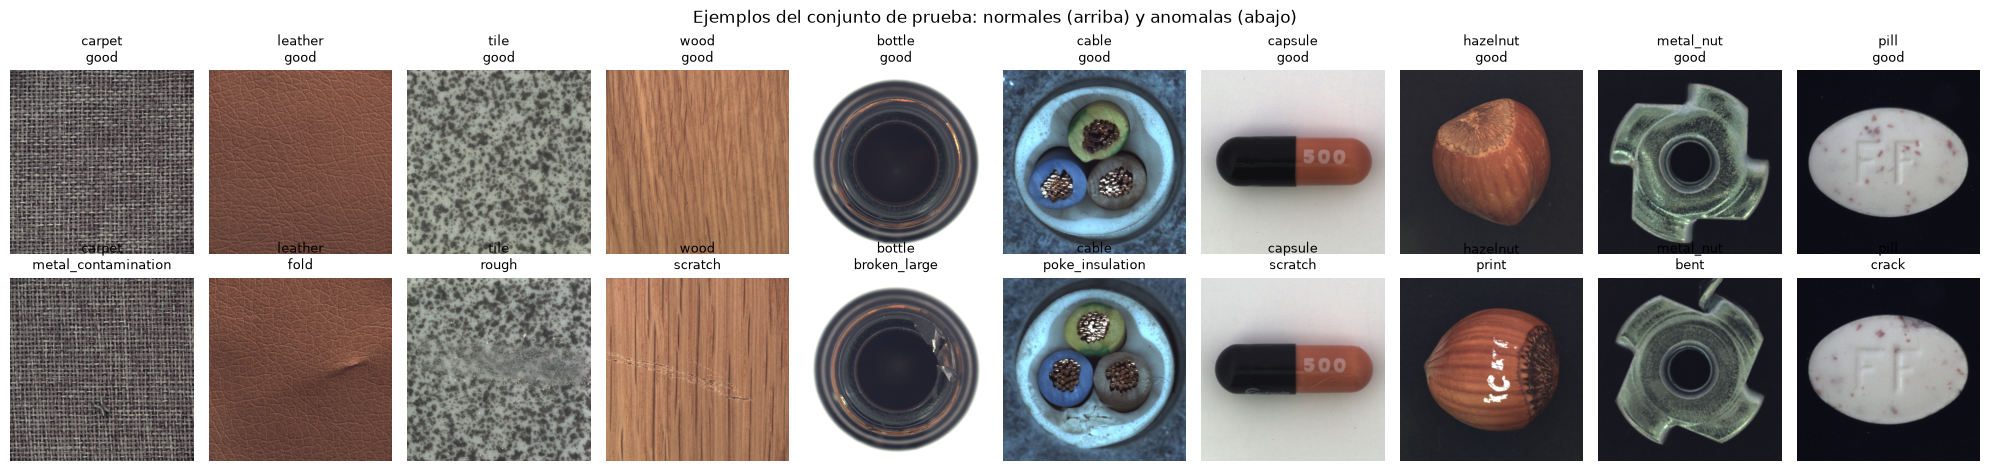

In [7]:
# Examples of the test set: normal (top row) and anomalous (bottom row)
rng = np.random.default_rng(cfg.seed)
fig, axes = plt.subplots(2, len(categories), figsize=(2 * len(categories), 4.8))
for j, category in enumerate(categories):
    for i, label in enumerate((0, 1)):
        rows = index[(index.category == category) & is_test & (index.label == label)]
        row = rows.iloc[rng.integers(len(rows))]
        with Image.open(data_root / row.path) as img:
            axes[i, j].imshow(img.convert("RGB"))
        axes[i, j].set_title(f"{category}\n{row.defect}", fontsize=9)
        axes[i, j].axis("off")
fig.suptitle("Ejemplos del conjunto de prueba: normales (arriba) y anomalas (abajo)")
plt.tight_layout()
plt.show()

## 3. Carga de datos con `LightningDataModule`

### 3.1 Decisiones de preprocesamiento
**Validación.** MVTec AD no trae un conjunto de validación, así que se separa el 20 % de `train/good` de cada categoría con una semilla fija. La separación es estratificada por categoría para que todas queden representadas en la misma proporción. La validación cumple dos funciones. Durante el entrenamiento la usa `EarlyStopping` para detectar overfitting, y en `anomalias.ipynb` sus embeddings sirven para estimar la distribución de lo normal (media y covarianza) de cada categoría. Ninguna imagen defectuosa entra en entrenamiento ni en validación. Las anomalías solo aparecen en el conjunto de prueba.

**Cache en memoria.** Cada imagen se decodifica y se redimensiona una sola vez y se guarda como tensor `uint8` en un cache (unos 560 MB). El cache también se guarda en `outputs/cache/`, así que las ejecuciones siguientes lo cargan en segundos. Con los datos ya en memoria leer un batch es solo indexar y normalizar, así que no hacen falta procesos auxiliares (`num_workers: 0`). En Windows además cada proceso auxiliar recibiría una copia del tensor. Así cada época es más rápida que leer de disco, porque ya no se decodifican imágenes de hasta 1024 px.

**Normalización.** Se usan la media y la desviación estándar de ImageNet, porque el teacher del modelo B es un ResNet-18 preentrenado en ImageNet y espera entradas con esa escala. Para que la comparación sea justa los tres modelos reciben exactamente el mismo preprocesamiento.

**Sin aumentación de datos.** Las transformaciones típicas como voltear o rotar pueden convertir una imagen normal en algo que en MVTec AD cuenta como defecto. Por ejemplo, `metal_nut` tiene un tipo de defecto llamado `flip`, que es la pieza volteada. Si el modelo viera esas transformaciones como normales aprendería a aceptar ese defecto. Por eso no se aplica aumentación.

### 3.2 Implementación
El código está en `src/data.py`. `MVTecDataset` toma las imágenes del cache y las normaliza al pedir cada elemento. `MVTecDataModule` construye el cache en `prepare_data`, hace la separación en `setup` y expone un `DataLoader` por split. Cada elemento es un diccionario con la imagen, el índice de su categoría (la etiqueta de los modelos A y B) y la etiqueta normal o anómala.

### 3.3 Verificación del `DataModule`
La primera vez que se ejecuta, `prepare_data` construye el cache (tarda un par de minutos). Después se comprueba que cada split tiene lo que debe tener.

In [8]:
# Split sizes per category
datamodule = instantiate(cfg.data)  # conf/data/mvtec.yaml -> src.data.MVTecDataModule
datamodule.prepare_data()
datamodule.setup()

splits = {"train": datamodule.train_set, "val": datamodule.val_set, "test": datamodule.test_set}
split_summary = pd.DataFrame({name: ds.index.groupby("category").size() for name, ds in splits.items()}).loc[categories]
split_summary["test_anomalas"] = datamodule.test_set.index.groupby("category")["label"].sum()
split_summary.loc["total"] = split_summary.sum()
split_summary["val_pct"] = (100 * split_summary["val"] / (split_summary["train"] + split_summary["val"])).round(1)
split_summary

,train,val,test,test_anomalas,val_pct
category,,,,,
carpet,224,56,117,89,20.0
leather,196,49,124,92,20.0
tile,184,46,117,84,20.0
wood,198,49,79,60,19.8
bottle,167,42,83,63,20.1
cable,179,45,150,92,20.1
capsule,175,44,132,109,20.1
hazelnut,313,78,110,70,19.9
metal_nut,176,44,115,93,20.0


In [9]:
# Checks: no defective image in train or val, no overlap, test has normals and anomalies
for name in ("train", "val"):
    ds_index = splits[name].index
    assert (ds_index["label"] == 0).all(), name
    assert (ds_index["defect"] == "good").all(), name
    assert (ds_index["split"] == "train").all(), name

# Train and val do not share images, and together they cover all of train/good
train_paths = set(datamodule.train_set.index["path"])
val_paths = set(datamodule.val_set.index["path"])
assert train_paths.isdisjoint(val_paths)
assert len(train_paths) + len(val_paths) == (index.split == "train").sum()

# Test has normal and anomalous images of every category
test_index = datamodule.test_set.index
assert set(test_index["category"]) == set(categories)
assert set(test_index.groupby("category")["label"].nunique()) == {2}

print("Verificaciones superadas")

Verificaciones superadas


In [10]:
# Shape, type and range of one batch of each split
for name, loader in [("train", datamodule.train_dataloader()),
                     ("val", datamodule.val_dataloader()),
                     ("test", datamodule.test_dataloader())]:
    batch = next(iter(loader))
    x = batch["image"]
    print(f"{name:5s} image {tuple(x.shape)} {x.dtype} rango [{x.min():.2f}, {x.max():.2f}]"
          f" | category {tuple(batch['category'].shape)} | labels {batch['label'].unique().tolist()}"
          f" | {len(loader)} batches")

train image (32, 3, 224, 224) torch.float32 rango [-2.02, 2.64] | category (32,) | labels [0] | 64 batches
val   image (32, 3, 224, 224) torch.float32 rango [-1.93, 1.75] | category (32,) | labels [0] | 16 batches
test  image (32, 3, 224, 224) torch.float32 rango [-1.90, 1.78] | category (32,) | labels [1] | 38 batches


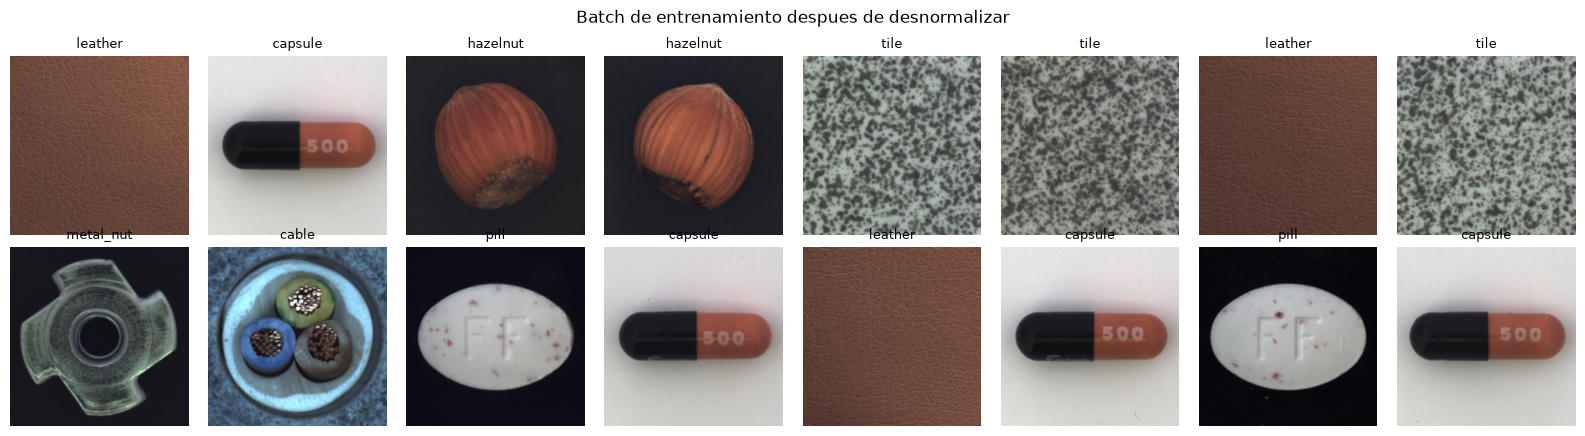

In [11]:
# One training batch after undoing the normalization
batch = next(iter(datamodule.train_dataloader()))
mean = torch.tensor(cfg.data.mean).view(1, 3, 1, 1)
std = torch.tensor(cfg.data.std).view(1, 3, 1, 1)
images = (batch["image"][:16] * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, image, category in zip(axes.flat, images, batch["category"][:16]):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(categories[category], fontsize=9)
    ax.axis("off")
fig.suptitle("Batch de entrenamiento despues de desnormalizar")
plt.tight_layout()
plt.show()